# Практика 2. Кварталы и метрики города: Барселона, район Eixample

**Курс:** «Технологии искусственного интеллекта в урбанистике»
**Территория:** l'Eixample, Barcelona, Catalonia, Spain (7,5 км²)
**Библиотека:** BlocksNet 1.0.0a9, Python 3.12

## Зачем этот ноутбук

Ноутбук шаг за шагом превращает данные OpenStreetMap в анализ городских кварталов:
скачивает объекты, режет территорию на кварталы, считает показатели BlocksNet
и сохраняет результаты в GeoJSON. Эти же файлы потом читает `dashboard.py`,
который собирает страницу `dashboard.html`.

## Источники данных

| Что | Откуда | Примечание |
|---|---|---|
| Граница района | OpenStreetMap / Nominatim (`osmnx.geocode_to_gdf`) | l'Eixample, Barcelona |
| Дороги, железные дороги, вода | OpenStreetMap | через `osmnx` или локальную выгрузку Geofabrik |
| Землепользование | OpenStreetMap, тег `landuse` | покрывает не всю территорию |
| Здания | OpenStreetMap, тег `building` | 8 199 полигонов |
| Школы | OpenStreetMap, `amenity=school` | 63 объекта |

## Как запускать

1. Активируйте окружение: `.venv\Scripts\Activate.ps1`
2. В VS Code откройте этот файл и выберите ядро `.venv` (Python 3.12.10).
3. Выполняйте ячейки по порядку кнопкой ▶ слева от ячейки.
4. Дойдя до отметки **⛔ ОСТАНОВКА** — прочитайте раздел про метрики, затем продолжайте.

## Что получится

- `data/*.geojson` — исходные слои и результаты по кварталам;
- `data/accessibility_matrix.pkl` — матрица времени в пути;
- `data/blocks_metrics.geojson` — главный результат: все показатели по кварталам.


## План работы

| Этап | Что делаем | Результат |
|---|---|---|
| 1 | Граница территории | `boundaries.geojson`, карта |
| 2 | Данные OSM | `roads/railways/water/landuse/buildings/schools.geojson` |
| 3 | Нарезка кварталов | `blocks.geojson`, карта кварталов |
| ⛔ | Знакомство с метриками | объяснение показателей |
| 4 | Землепользование | доли функций, преобладающая функция |
| 5 | Транспорт | пешеходный граф, матрица времени (мин) |
| 6 | Здания и население | население по кварталам (оценка) |
| 7 | Школы | число школ и вместимость |
| 8 | Обеспеченность | provision strong/weak, дефицит мест |
| 9 | Плотность | FSI, GSI, MXI, OSR |
| 10 | Типы застройки | Spacematrix и «Стрелка» |
| 11 | Доступность с учётом площади | area_accessibility |
| 12 | Сводка | `blocks_metrics.geojson`, таблица, дашборд |


In [1]:
import os
import pickle

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd

from blocksnet.blocks.cutting import cut_urban_blocks, preprocess_urban_objects
from blocksnet.blocks.assignment import assign_land_use
from blocksnet.blocks.postprocessing import postprocess_urban_blocks
from blocksnet.blocks.aggregation import aggregate_objects
from blocksnet.preprocessing.imputing import impute_buildings, impute_services
from blocksnet.relations import calculate_accessibility_matrix
from blocksnet.analysis.indicators import calculate_density_indicators
from blocksnet.analysis.morphotypes import get_spacematrix_morphotypes, get_strelka_morphotypes
from blocksnet.analysis.network import area_accessibility
from blocksnet.analysis.provision import competitive_provision
from blocksnet.config import service_types_config
from blocksnet.enums import LandUse

DATA_ROOT_HINT = os.getcwd()

def find_project_root():
    for cand in (os.getcwd(), os.path.abspath(os.path.join(os.getcwd(), ".."))):
        if os.path.exists(os.path.join(cand, "pyproject.toml")):
            return cand
    return os.getcwd()

ROOT = find_project_root()
DATA = os.path.join(ROOT, "data")
os.makedirs(DATA, exist_ok=True)
CRS = "EPSG:32631"  # UTM 31N — метры, удобно для площадей и расстояний
print("корень проекта:", ROOT)

def path(name):
    return os.path.join(DATA, name)

def save(gdf, name):
    gdf.to_file(path(name), driver="GeoJSON")
    print(f"сохранено {name}: {len(gdf)} объектов")

def load(name):
    p = path(name)
    return gpd.read_file(p) if os.path.exists(p) else None

print("окружение готово, папка данных:", DATA)

C:\ai-course\python-package-boilerplate\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


корень проекта: C:\ai-course\python-package-boilerplate
окружение готово, папка данных: C:\ai-course\python-package-boilerplate\data


## Этап 1. Граница территории

Берём административную границу района через Nominatim. Всё дальше считаем в метрах
(UTM 31N), поэтому площади и расстояния получаются в гектарах и метрах.


объектов: 1
площадь, га: 750.1


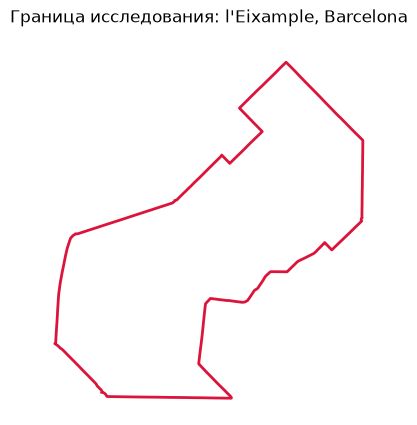

In [2]:
boundaries = load("boundaries.geojson")

if boundaries is None:
    import osmnx as ox
    boundaries = ox.geocode_to_gdf("Eixample, Barcelona, Spain")
    boundaries = boundaries.to_crs(CRS)

print("объектов:", len(boundaries))
print("площадь, га:", round(boundaries.area.sum() / 1e4, 1))

ax = boundaries.plot(facecolor="none", edgecolor="crimson", linewidth=2)
ax.set_title("Граница исследования: l'Eixample, Barcelona")
ax.set_axis_off();

## Этап 2. Данные OpenStreetMap

Нужны шесть слоёв: дороги, железные дороги, вода, землепользование, здания и школы.
Если файлы уже лежат в `data/` — они просто читаются (повторный запуск не тратит время
и не зависит от доступности Overpass).

> **Про источник.** В этой работе данные один раз выгружены из региональной выгрузки
> Geofabrik (`cataluna-261019.osm.pbf`, **дата выгрузки — 19.10.2026**) и обрезаны по границе района: Overpass в дни работы
> был перегружен. Ячейка ниже умеет и то, и другое: сначала пробует готовые файлы,
> иначе скачивает через `osmnx.features_from_polygon`.


In [3]:
import osmnx as ox


def osm_layer(name, tags, keep_geom=("Polygon", "MultiPolygon", "LineString", "MultiLineString")):
    cached = load(f"{name}.geojson")
    if cached is not None:
        print(f"{name}: из кэша, {len(cached)} объектов")
        return cached
    poly = boundaries.to_crs(4326).union_all()
    gdf = ox.features_from_polygon(poly, tags=tags)
    gdf = gdf[gdf.geom_type.isin(keep_geom)].to_crs(CRS)
    gdf = gpd.clip(gdf, boundaries)
    gdf = gdf[~gdf.geometry.is_empty]
    save(gdf, f"{name}.geojson")
    return gdf


HIGHWAY = ["motorway", "motorway_link", "trunk", "trunk_link", "primary", "primary_link",
           "secondary", "secondary_link", "tertiary", "tertiary_link", "residential",
           "living_street", "pedestrian", "unclassified", "services", "road"]

roads = load("roads.geojson")
railways = load("railways.geojson")
water = load("water.geojson")
landuse = load("landuse.geojson")
buildings = load("buildings.geojson")
schools = load("schools.geojson")

for name, gdf in (("roads", roads), ("railways", railways), ("water", water),
                  ("landuse", landuse), ("buildings", buildings), ("schools", schools)):
    n = 0 if gdf is None else len(gdf)
    print(f"{name:>10}: {n:>6} объектов")

     roads:   2423 объектов
  railways:     66 объектов
     water:      0 объектов
   landuse:    344 объектов
 buildings:   8199 объектов
   schools:     63 объектов


## Этап 3. Нарезка кварталов

Кварталы строятся геометрически: дороги и железные дороги превращаются в линии-барьеры,
вода — в полигоны-барьеры, и территория режется на замкнутые ячейки.

1. `preprocess_urban_objects` — чистит и объединяет барьеры.
2. `cut_urban_blocks` — режет территорию по барьерам.
3. `postprocess_urban_blocks` — убирает геометрические артефакты.

Границы кварталов — расчётные, они не совпадают с официальным кадастром:
квартал здесь — это участок между осями улиц.


In [4]:
lines, polygons = preprocess_urban_objects(roads, railways, water if water is not None and len(water) else None)
print("барьеры: линий", len(lines), "| полигонов", len(polygons))

blocks = cut_urban_blocks(boundaries, lines, polygons, buildings)
blocks = postprocess_urban_blocks(blocks)
blocks["area_ha"] = blocks.area / 1e4
print("кварталов:", len(blocks))
print("площадь, га:", round(blocks["area_ha"].sum(), 1))
print(blocks["area_ha"].describe().round(2).to_string())

2026-10-21 00:22:12.640 | INFO     | blocksnet.blocks.cutting.preprocessing.core:preprocess_urban_objects:44 - Checking roads schema


2026-10-21 00:22:12.669 | INFO     | blocksnet.blocks.cutting.preprocessing.core:preprocess_urban_objects:51 - Checking railways schema


2026-10-21 00:22:12.683 | INFO     | blocksnet.blocks.cutting.preprocessing.core:preprocess_urban_objects:58 - Checking water schema


2026-10-21 00:22:12.684 | WARNING  | blocksnet.blocks.cutting.preprocessing.core:preprocess_urban_objects:60 - Creating empty water


2026-10-21 00:22:12.696 | INFO     | blocksnet.blocks.cutting.processing.schemas:validate_and_preprocess_gdfs:51 - Checking boundaries schema


...

2026-10-21 00:22:12.735 | WARNING  | blocksnet.blocks.cutting.processing.schemas:validate_and_preprocess_gdfs:64 - Creating empty polygon objects


2026-10-21 00:22:12.739 | INFO     | blocksnet.blocks.cutting.processing.schemas:validate_and_preprocess_gdfs:69 - Checking buildings schema


барьеры: линий 2489 | полигонов 0


2026-10-21 00:22:12.924 | SUCCESS  | blocksnet.blocks.cutting.processing.core:cut_urban_blocks:26 - 1039 blocks are successfully cut


кварталов: 1039
площадь, га: 750.1
count    1039.00
mean        0.72
std         0.94
min         0.00
25%         0.04
50%         0.23
75%         1.62
max        11.25


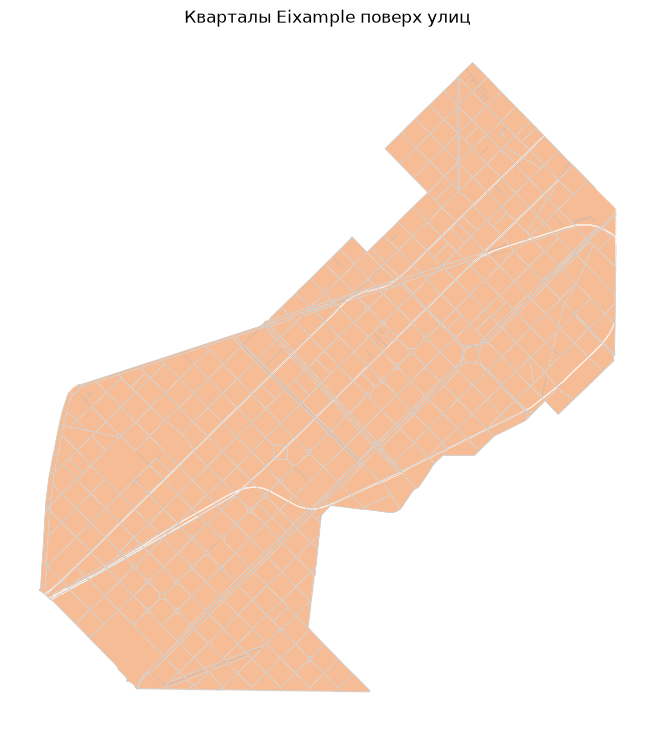

In [5]:
ax = roads.plot(color="#bbb", linewidth=0.4, figsize=(9, 9))
blocks.plot(ax=ax, facecolor="#f4b183", edgecolor="white", linewidth=0.4, alpha=0.85)
ax.set_title("Кварталы Eixample поверх улиц")
ax.set_axis_off();

In [6]:
blocks.to_file(path("blocks.geojson"), driver="GeoJSON")
print("кварталы сохранены в blocks.geojson")

кварталы сохранены в blocks.geojson


---
# ⛔ ОСТАНОВКА после подготовки кварталов

Дальше начинаются расчёты. Прежде чем их запускать — что вообще считает BlocksNet.

| Группа | Что показывает | Единицы |
|---|---|---|
| **Землепользование** | какая функция преобладает в квартале и доли функций | категория, доли 0–1 |
| **Транспорт** | сколько минут пешком от квартала до квартала | минуты |
| **Здания и население** | плотность застройки, площадь этажей, оценка населения | м², чел. |
| **Школы** | число школ в квартале и вместимость | шт., места |
| **Обеспеченность** | сколько мест доступно относительно спроса, дефицит/остаток | места, доля 0–1 |
| **Плотность** | FSI, GSI, MXI, OSR, доля жилых площадей | коэффициенты, доли |
| **Типы застройки** | морфотипы Spacematrix и классификация «Стрелки» | категории |
| **Доступность с учётом площади** | среднее время пешком до всех кварталов, взвешенное по их площади: чем меньше, тем «центральнее» квартал | минуты |

Важно: население, вместимость школ и часть этажности — **модельные оценки**,
а не официальная статистика. В таблицах они помечены.


## Этап 4. Землепользование

Функциональные зоны OSM пересекаются с кварталами; побеждает функция с наибольшей долей площади.
Если квартал не попал ни в одну зону OSM — остаётся без метки (в Eixample так у 772 из 1039 кварталов, 74%:
OSM `landuse` покрывает не всё, особенно плотную жилую застройку). Ниже такие кварталы дополнительно
оцениваются по составу застройки.


In [7]:
RULES = {
    "commercial": LandUse.BUSINESS, "industrial": LandUse.INDUSTRIAL, "cemetery": LandUse.SPECIAL,
    "garages": LandUse.INDUSTRIAL, "residential": LandUse.RESIDENTIAL, "retail": LandUse.BUSINESS,
    "grass": LandUse.RECREATION, "farmland": LandUse.AGRICULTURE, "construction": LandUse.SPECIAL,
    "brownfield": LandUse.INDUSTRIAL, "forest": LandUse.RECREATION, "recreation_ground": LandUse.RECREATION,
    "religious": LandUse.SPECIAL, "flowerbed": LandUse.RECREATION, "military": LandUse.SPECIAL,
    "landfill": LandUse.TRANSPORT,
    # расширенные значения, которые реально встречаются в Eixample
    "meadow": LandUse.RECREATION, "village_green": LandUse.RECREATION, "greenery": LandUse.RECREATION,
    "allotments": LandUse.AGRICULTURE, "plant_nursery": LandUse.AGRICULTURE,
    "greenfield": LandUse.RECREATION, "education": LandUse.SPECIAL,
    "harbour": LandUse.TRANSPORT, "railway": LandUse.TRANSPORT, "traffic_island": LandUse.TRANSPORT,
    "basin": LandUse.RECREATION,
}

zones = landuse.rename(columns={"landuse": "functional_zone"})[["functional_zone", "geometry"]]
blocks_lu = assign_land_use(blocks, zones, RULES)
blocks_lu["area_ha"] = blocks_lu.area / 1e4
blocks_lu["land_use_source"] = blocks_lu["land_use"].notna().map({True: "osm", False: "none"})
print(blocks_lu["land_use"].value_counts(dropna=False).to_string())
print("метка из OSM:", int((blocks_lu["land_use_source"] == "osm").sum()), "из", len(blocks_lu))

land_use
None                   772
LandUse.RESIDENTIAL    147
LandUse.RECREATION      79
LandUse.BUSINESS        18
LandUse.SPECIAL         14
LandUse.INDUSTRIAL       5
LandUse.TRANSPORT        2
LandUse.AGRICULTURE      2
метка из OSM: 267 из 1039


In [8]:
# Кварталы, не попавшие ни в одну зону OSM: оцениваем функцию по составу застройки.
# Правило простое: если >= 50% зданий квартала одного типа — берём соответствующую функцию.
# Это ОЦЕНКА, а не данные OSM; источник помечен в колонке land_use_source.
BUILDING_GROUPS = {
    "residential": {"residential", "house", "apartments", "detached", "terrace", "dormitory",
                    "yes", "bungalow", "cabin", "farm", "semidetached_house"},
    "business": {"retail", "commercial", "office", "hotel", "supermarket", "mall", "kiosk",
                 "restaurant", "cafe", "shop", "bank"},
    "industrial": {"industrial", "warehouse", "factory", "manufacture", "storage_tank", "silo"},
    "public": {"school", "university", "civic", "public", "government", "hospital", "church",
               "cathedral", "chapel", "museum", "kindergarten", "college"},
}
TO_LAND_USE = {"residential": LandUse.RESIDENTIAL, "business": LandUse.BUSINESS,
               "industrial": LandUse.INDUSTRIAL, "public": LandUse.SPECIAL}

bt = buildings[["building", "geometry"]].copy()
bt["group"] = bt["building"].fillna("yes").map(
    {t: g for g, types in BUILDING_GROUPS.items() for t in types})
joined = gpd.sjoin(bt[["group", "geometry"]].dropna(subset=["group"]),
                   blocks_lu[["geometry"]], predicate="intersects", how="inner")
shares = joined.groupby(["index_right", "group"]).size().unstack(fill_value=0)
shares = shares.div(shares.sum(axis=1), axis=0)
dominant, confidence = shares.idxmax(axis=1), shares.max(axis=1)
mapped = dominant.map(TO_LAND_USE)

candidates = mapped.index[(confidence >= 0.5) & mapped.notna()]
candidates = [i for i in candidates if i in blocks_lu.index and pd.isna(blocks_lu.at[i, "land_use"])]
blocks_lu.loc[candidates, "land_use"] = mapped.loc[candidates]
blocks_lu.loc[candidates, "land_use_source"] = "buildings"

print(blocks_lu["land_use_source"].value_counts().to_string())
print("с функцией всего:", int(blocks_lu["land_use"].notna().sum()), "из", len(blocks_lu))

land_use_source
none         480
buildings    292
osm          267
с функцией всего: 559 из 1039


**Почему без метки остались 480 кварталов.** Это в основном мелкие осколки между улицами
и технические полосы: у них нет зданий, а зоны OSM тоже не покрывают. Они остаются в файле,
но в выводах мы считаем показатели по застроенным кварталам — их 437 и они занимают 92% площади.


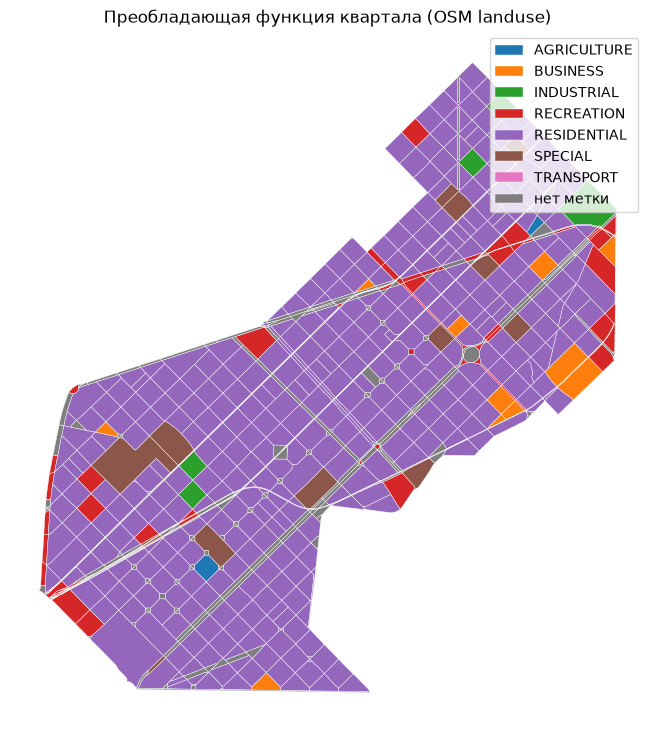

In [9]:
share_cols = [c for c in blocks_lu.columns if c in ("residential", "business", "recreation",
                                                      "industrial", "transport", "special", "agriculture")]
lu_plot = blocks_lu.copy()
lu_plot["lu"] = lu_plot["land_use"].astype(str).str.replace("LandUse.", "", regex=False).replace("None", "нет метки")
ax = lu_plot.plot(color="#eee", edgecolor="white", figsize=(9, 9))
lu_plot.plot(column="lu", categorical=True, legend=True, ax=ax, edgecolor="white", linewidth=0.3)
ax.set_title("Преобладающая функция квартала (OSM landuse)")
ax.set_axis_off();

## Этап 5. Транспорт: пешеходный граф и время в пути

Берём **готовый пешеходный граф** OSM (`iduedu.get_walk_graph`) — без интермодального графа
и без общественного транспорта. Скорость 5 км/ч, время на рёбрах — минуты.
Матрица `calculate_accessibility_matrix` даёт время пешком от каждого квартала до каждого.


In [10]:
GRAPH_PATH = path("walk_graph.pkl")
if os.path.exists(GRAPH_PATH):
    with open(GRAPH_PATH, "rb") as fh:
        graph = pickle.load(fh)
    print("граф из кэша:", graph.number_of_nodes(), "узлов,", graph.number_of_edges(), "рёбер")
else:
    import iduedu as ie
    graph = ie.get_walk_graph(polygon=boundaries.to_crs(4326).union_all(), walk_speed=83.3333)
    with open(GRAPH_PATH, "wb") as fh:
        pickle.dump(graph, fh)
    print("граф построен:", graph.number_of_nodes(), "узлов,", graph.number_of_edges(), "рёбер")

print("источник: OpenStreetMap, пешеходная сеть, скорость 5 км/ч")
print("CRS графа:", graph.graph.get("crs"))

граф из кэша: 6952 узлов, 21726 рёбер
источник: OpenStreetMap, пешеходная сеть, скорость 5 км/ч
CRS графа: 32631


In [11]:
acc_mx = calculate_accessibility_matrix(blocks_lu, graph)
acc_mx.to_pickle(path("accessibility_matrix.pkl"))
print("матрица:", acc_mx.shape)
print("время пешком, мин:", acc_mx.stack().describe()[["min", "50%", "max"]].round(1).to_dict())

матрица: (1039, 1039)
время пешком, мин: {'min': 0.0, '50%': 22.2, 'max': 65.0}


C:\ai-course\python-package-boilerplate\.venv\Lib\site-packages\pandas\core\nanops.py:1487: RuntimeWarning: overflow encountered in cast
  return dtype.type(n)
C:\ai-course\python-package-boilerplate\.venv\Lib\site-packages\numpy\_core\_methods.py:52: RuntimeWarning: overflow encountered in reduce
  return umr_sum(a, axis, dtype, out, keepdims, initial, where)
C:\ai-course\python-package-boilerplate\.venv\Lib\site-packages\pandas\core\nanops.py:731: RuntimeWarning: invalid value encountered in scalar divide
  the_mean = the_sum / count if count > 0 else np.nan


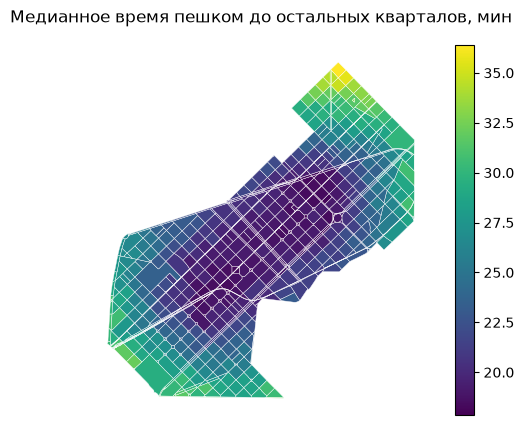

In [12]:
median_time = acc_mx.median(axis=1)
ax = blocks_lu.plot(color="#eee", edgecolor="white")
blocks_lu.assign(median_time=median_time).plot(column="median_time", cmap="viridis", legend=True,
                                               ax=ax, edgecolor="white", linewidth=0.3)
ax.set_title("Медианное время пешком до остальных кварталов, мин")
ax.set_axis_off();

## Этап 6. Здания и население

Из OSM берём тип здания и этажность (`building:levels`). Этажность известна у 67% зданий;
остальное достраивается моделью BlocksNet. Население — **оценка**: площадь жилых этажей
делится на норму 30 м²/чел.

> Проверка: для Eixample модель даёт ~324 тыс. человек при официальных ~265 тыс.
> Оценка завышена примерно на 20% — это ожидаемо и отмечено в выводах.


In [13]:
def tag(series, key):
    return series.fillna("").str.extract(r'"' + key + r'"=>"([^"]*)"', expand=False)


IS_LIVING = ["residential", "house", "apartments", "detached", "terrace", "dormitory"]
buildings["is_living"] = buildings["building"].isin(IS_LIVING)
buildings["number_of_floors"] = pd.to_numeric(tag(buildings["other_tags"], "building:levels"), errors="coerce")
print("жилых зданий:", int(buildings["is_living"].sum()), "из", len(buildings))
print("этажность известна у:", int(buildings["number_of_floors"].notna().sum()))

buildings = impute_buildings(buildings, default_living_demand=30)
print("оценка населения района, чел.:", int(buildings["population"].sum()))

2026-10-21 00:22:26.483 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column footprint_area not found and will be initialized as None


2026-10-21 00:22:26.484 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column build_floor_area not found and will be initialized as None


2026-10-21 00:22:26.485 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column living_area not found and will be initialized as None


2026-10-21 00:22:26.487 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column non_living_area not found and will be initialized as None


2026-10-21 00:22:26.488 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column population not found and will be initialized as None


жилых зданий: 6627 из 8199
этажность известна у: 4158
оценка населения района, чел.: 324283


2026-10-21 00:22:26.612 | INFO     | blocksnet.blocks.aggregation.core:_preprocess_input:12 - Preprocessing input


2026-10-21 00:22:26.632 | INFO     | blocksnet.blocks.aggregation.core:aggregate_objects:41 - Aggregating objects


кварталов со зданиями: 437 из 1039
застроенная площадь, га: 386.1


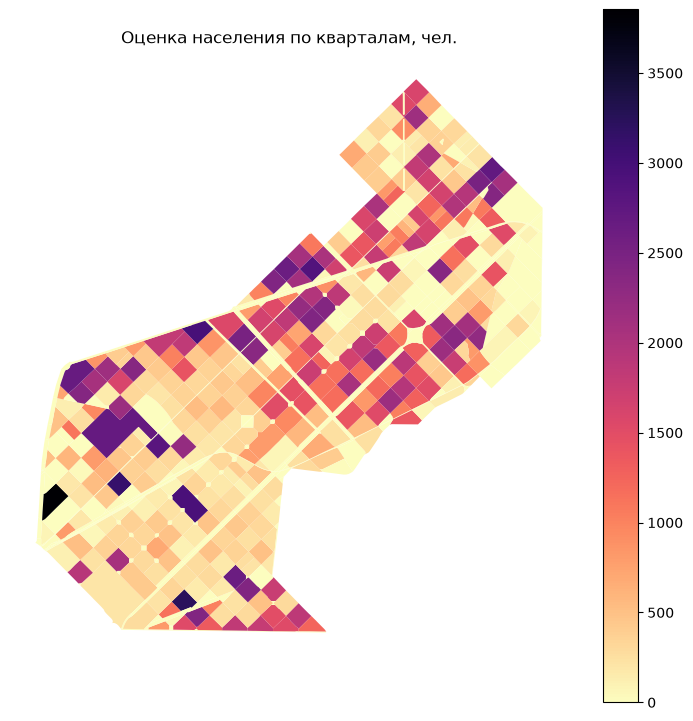

In [14]:
buildings_blocks, _ = aggregate_objects(blocks_lu, buildings)
buildings_blocks = buildings_blocks.drop(columns=["geometry"])
blocks_lu = blocks_lu.join(buildings_blocks)
print("кварталов со зданиями:", int((buildings_blocks["footprint_area"] > 0).sum()), "из", len(blocks_lu))
print("застроенная площадь, га:", round(buildings_blocks["footprint_area"].sum() / 1e4, 1))

ax = blocks_lu.plot(column="population", cmap="magma_r", legend=True, figsize=(9, 9))
ax.set_title("Оценка населения по кварталам, чел.")
ax.set_axis_off();

## Этап 7. Школы

Школы берём из OSM (`amenity=school`): 39 полигонов и 24 отдельные точки, дубликаты убраны.
Вместимость в OSM почти не заполнена, поэтому BlocksNet оценивает её по площади здания —
это **модельная оценка**.


In [15]:
school_polys = schools[schools.geom_type.isin(["Polygon", "MultiPolygon"])]
school_pts = schools[schools.geom_type.isin(["Point", "MultiPoint"])]
if len(school_pts) and len(school_polys):
    inner = gpd.sjoin(school_pts, school_polys[["geometry"]], predicate="within", how="inner")
    school_pts = school_pts.drop(index=inner.index.unique())
schools_dedup = pd.concat([school_polys, school_pts], ignore_index=True)
schools_dedup = gpd.GeoDataFrame(schools_dedup, geometry="geometry", crs=CRS)

schools_dedup = impute_services(schools_dedup, "school")
print("школ:", len(schools_dedup))
print("суммарная вместимость (оценка), мест:", int(schools_dedup["capacity"].sum()))

schools_blocks, _ = aggregate_objects(blocks_lu, schools_dedup)
schools_blocks = schools_blocks.drop(columns=["geometry"])
print("кварталов со школами:", int((schools_blocks["count"] > 0).sum()))

2026-10-21 00:22:27.284 | INFO     | blocksnet.blocks.aggregation.core:_preprocess_input:12 - Preprocessing input


2026-10-21 00:22:27.286 | INFO     | blocksnet.blocks.aggregation.core:aggregate_objects:41 - Aggregating objects


школ: 63
суммарная вместимость (оценка), мест: 15750
кварталов со школами: 53


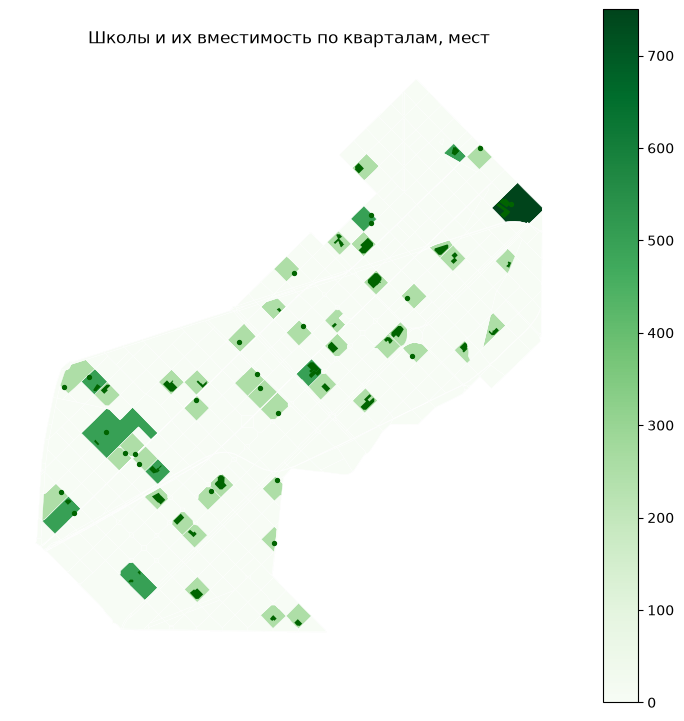

In [16]:
ax = blocks_lu.plot(color="#eee", edgecolor="white", figsize=(9, 9))
schools_blocks.assign(geom=blocks_lu.geometry).set_geometry("geom").plot(
    column="capacity", cmap="Greens", legend=True, ax=ax, edgecolor="white", linewidth=0.3)
schools_dedup.plot(ax=ax, color="darkgreen", markersize=8)
ax.set_title("Школы и их вместимость по кварталам, мест")
ax.set_axis_off();

## Этап 8. Обеспеченность школами

`competitive_provision` распределяет спрос (население) между школами в пределах 15 минут пешком
и считает два показателя:

- **provision_strong** — доля спроса, покрытая местами с учётом конкуренции соседних кварталов;
- **provision_weak** — мягкая версия, когда места считаются доступными шире.

Спрос: 120 мест на 1000 жителей (норматив BlocksNet для школ).


In [17]:
df = blocks_lu[["population"]].join(schools_blocks[["capacity"]], how="left").fillna({"capacity": 0})
cfg = service_types_config["school"]
print("норматив:", cfg)

prov_df, links_df = competitive_provision(df, acc_mx, cfg["accessibility"], cfg["demand"])
print("показатели:", list(prov_df.columns))
print("дефицит мест, сумма:", int(prov_df["demand_left"].sum()))
print("кварталов с обеспеченностью > 0:", int((prov_df["provision_strong"] > 0).sum()))

2026-10-21 00:22:28.363 | INFO     | blocksnet.analysis.provision.competitive.core:_initialize_provision_df:29 - Initializing provision DataFrame


2026-10-21 00:22:28.364 | WARNING  | blocksnet.analysis.provision.competitive.core:_initialize_provision_df:33 - No demand in columns. Imputing using population column and demand parameter


2026-10-21 00:22:28.383 | INFO     | blocksnet.analysis.provision.competitive.core:_supply_self:56 - Supplying blocks with own capacities


2026-10-21 00:22:28.412 | INFO     | blocksnet.analysis.provision.competitive.core:competitive_provision:190 - Setting and solving LP problems until max depth or break condition reached


норматив: {'name_ru': 'школа', 'demand': 120, 'accessibility': 15}


2026-10-21 00:22:29.415 | SUCCESS  | blocksnet.analysis.provision.competitive.core:competitive_provision:203 - Provision assessment finished


показатели: ['demand', 'capacity', 'demand_left', 'demand_within', 'demand_without', 'capacity_left', 'capacity_within', 'capacity_without', 'provision_strong', 'provision_weak']
дефицит мест, сумма: 23353
кварталов с обеспеченностью > 0: 101


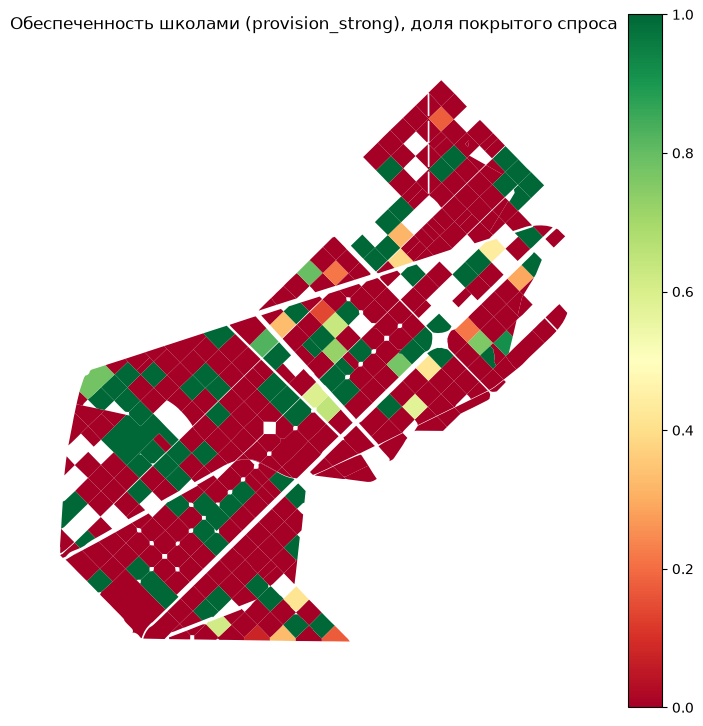

In [18]:
ax = blocks_lu.join(prov_df).plot(column="provision_strong", cmap="RdYlGn", vmin=0, vmax=1,
                                     legend=True, figsize=(9, 9))
ax.set_title("Обеспеченность школами (provision_strong), доля покрытого спроса")
ax.set_axis_off();

## Этап 9. Плотность застройки

`calculate_density_indicators` считает:

- **FSI** (floor space index) — отношение площади этажей к площади квартала;
- **GSI** (ground space index) — доля застроенной земли;
- **MXI** — индекс смешанности функций;
- **OSR** (open space ratio) — сколько открытого пространства приходится на площадь этажей;
- **share_living / share_non_living** — доли жилых и нежилых площадей.


In [19]:
bb = blocks_lu.copy()
bb["site_area"] = bb.area
density_df = calculate_density_indicators(bb)

built = density_df[density_df["footprint_area"] > 0]
print(density_df[["fsi", "gsi", "mxi", "osr"]].describe().round(2).to_string())

           fsi      gsi     mxi      osr
count  1039.00  1039.00  437.00  1039.00
mean      0.89     0.23    0.65      inf
std       1.57     0.29    0.32      NaN
min       0.00     0.00    0.00    -0.49
25%       0.00     0.00    0.50     0.41
50%       0.00     0.00    0.80      NaN
75%       0.81     0.55    0.90      NaN
max       6.88     1.00    0.90      inf


C:\ai-course\python-package-boilerplate\.venv\Lib\site-packages\pandas\core\nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
C:\ai-course\python-package-boilerplate\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:4653: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)


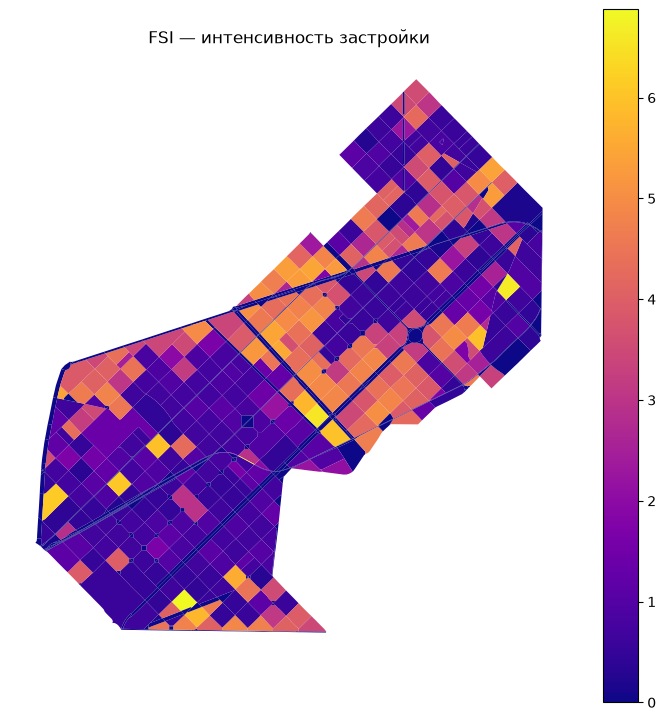

In [20]:
ax = blocks_lu.join(density_df, rsuffix="_d").plot(column="fsi", cmap="plasma", legend=True, figsize=(9, 9))
ax.set_title("FSI — интенсивность застройки")
ax.set_axis_off();

## Этап 10. Типы застройки: Spacematrix и «Стрелка»

Два независимых взгляда на морфологию:

- **Spacematrix** — сетка «плотность × этажность × открытые пространства» (11 кластеров);
- **«Стрелка»** — эмпирическая классификация: центральная, среднеэтажная, микрорайон и т. д.

Они не противоречат друг другу: Spacematrix описывает геометрию, «Стрелка» — узнаваемые типы.


In [21]:
spacematrix_df, spacematrix_clusters = get_spacematrix_morphotypes(density_df)
strelka_df = get_strelka_morphotypes(density_df)

print("Spacematrix:")
print(spacematrix_df["morphotype"].value_counts().to_string())
print("\nСтрелка:")
print(strelka_df["morphotype"].value_counts().to_string())

Spacematrix:
morphotype
high-mid-rise high-density residential        164
low-rise low-density residential              160
low-rise low-density non-residential           57
low-rise low-density mixed-use                 32
high-mid-rise high-density non-residential     16
mid-rise non-residential                        8

Стрелка:
morphotype
low-rise model                    205
central model                     128
low-rise non-residential           48
mid-rise                           19
high-rise modern microdistrict     12
mid-rise block                     12
mid-rise non-residential           10
high-rise non-residential           3


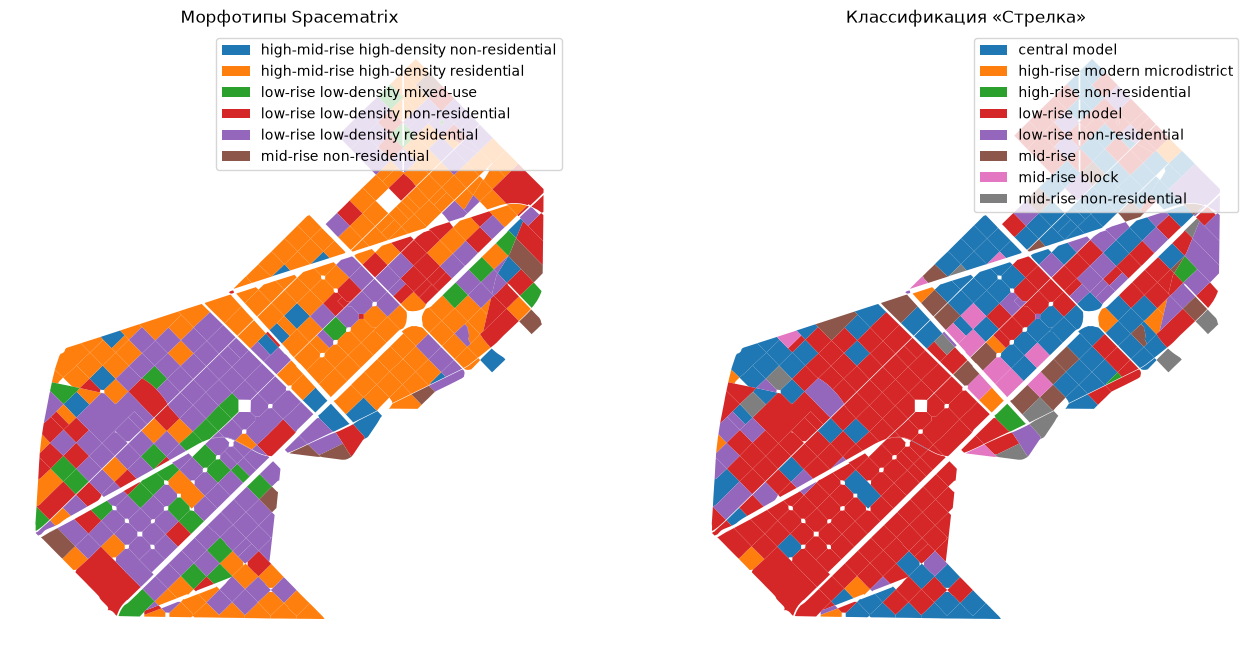

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
blocks_lu.join(spacematrix_df).plot(column="morphotype", categorical=True, legend=True, ax=axes[0])
axes[0].set_title("Морфотипы Spacematrix"); axes[0].set_axis_off()
blocks_lu.join(strelka_df).plot(column="morphotype", categorical=True, legend=True, ax=axes[1])
axes[1].set_title("Классификация «Стрелка»"); axes[1].set_axis_off()

## Этап 11. Доступность с учётом площади

`area_accessibility` — для каждого квартала **среднее время пешком (мин) до всех остальных кварталов,
взвешенное по их площади**: крупные кварталы весят больше мелких осколков. Чем меньше значение, тем
«центральнее» квартал в пешеходной сети; у кварталов на краю района значения выше.
Это не время до ближайшего сервиса и не «площадь, доступная за 15 минут».


       area_accessibility
count              1039.0
mean                 24.8
std                   4.0
min                  19.1
25%                  21.2
50%                  23.9
75%                  28.0
max                  37.0


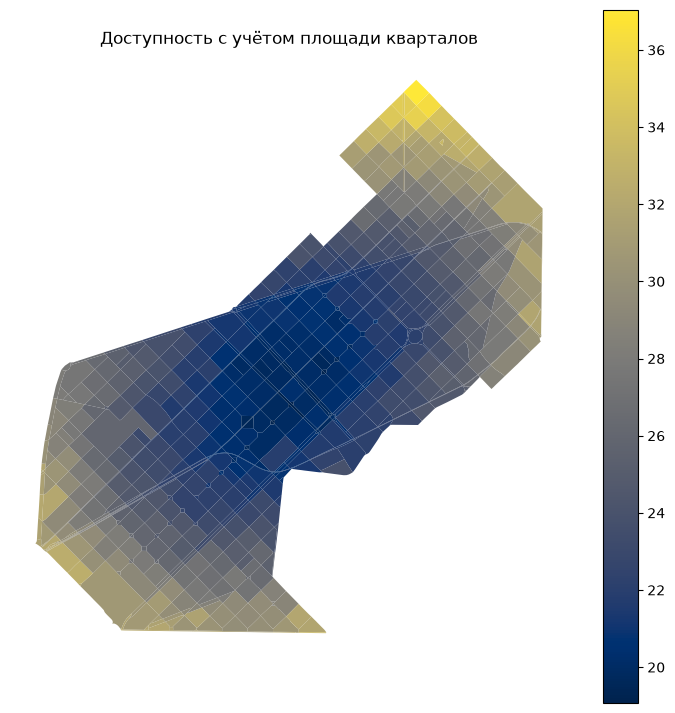

In [23]:
area_acc = area_accessibility(acc_mx, bb)
print(area_acc.describe().round(1).to_string())

ax = blocks_lu.join(area_acc).plot(column="area_accessibility", cmap="cividis", legend=True, figsize=(9, 9))
ax.set_title("Доступность с учётом площади кварталов")
ax.set_axis_off();

## Этап 12. Сводная таблица и экспорт

Собираем всё в один GeoJSON — его читает `dashboard.py`.
Кварталы без зданий (в основном мелкие осколки между улицами) остаются в файле,
но в выводах мы считаем показатели по застроенным.


In [24]:
bb["median_time_min"] = acc_mx.median(axis=1).reindex(bb.index)
dup = [c for c in density_df.columns if c in bb.columns]
result = (bb.join(density_df.drop(columns=dup))
            .join(spacematrix_df[["morphotype"]].astype(str).rename(columns={"morphotype": "spacematrix"}))
            .join(strelka_df[["morphotype"]].astype(str).rename(columns={"morphotype": "strelka"}))
            .join(prov_df)
            .join(area_acc))

f16 = [c for c in result.columns if str(result[c].dtype) == "float16"]
if f16:
    result[f16] = result[f16].astype("float64")
    print("float16 -> float64:", f16)

result.to_file(path("blocks_metrics.geojson"), driver="GeoJSON")
print("сохранено blocks_metrics.geojson:", len(result), "кварталов,", len(result.columns), "колонок")

float16 -> float64: ['median_time_min']


C:\ai-course\python-package-boilerplate\.venv\Lib\site-packages\pyogrio\raw.py:733: RuntimeWarning: NaN of Infinity value found. Skipped. Further messages of this type will be suppressed.
  ogr_write(


сохранено blocks_metrics.geojson: 1039 кварталов, 42 колонок


In [25]:
built = result[result["footprint_area"] > 0]
summary = pd.Series({
    "кварталов всего": len(result),
    "застроенных кварталов": len(built),
    "площадь территории, га": round(result["area_ha"].sum(), 1),
    "население (оценка), чел.": int(result["population"].sum()),
    "мест в школах (оценка)": int(result["capacity"].sum()),
    "медианный FSI": round(built["fsi"].median(), 2),
    "медианный GSI": round(built["gsi"].median(), 2),
    "медиана времени пешком, мин": round(acc_mx.median(axis=1).median(), 1),
    "кварталов с дефицитом школ": int((result["demand_left"] > 0).sum()),
})
print(summary.to_string())

кварталов всего                  1039.00
застроенных кварталов             437.00
площадь территории, га            750.10
население (оценка), чел.       324283.00
мест в школах (оценка)          15750.00
медианный FSI                       1.06
медианный GSI                       0.58
медиана времени пешком, мин        21.50
кварталов с дефицитом школ        307.00


## Сверка: показатель — где в ноутбуке — где в дашборде

| Показатель `pipeline.ipynb` | Ноутбук | Колонка `blocks_metrics.geojson` | Дашборд |
|---|---|---|---|
| Доли функций и преобладающая функция | Этап 4 | `residential` … `agriculture`, `land_use`, `land_use_source` | слой «Землепользование», подсказка квартала, график землепользования |
| Время в пути между кварталами | Этап 5 | `median_time_min` (матрица — `accessibility_matrix.pkl`) | слой «Медианное время пешком», карточка, подсказка |
| Здания: площадь застройки и этажей, жилая/нежилая | Этап 6 | `footprint_area`, `build_floor_area`, `living_area`, `non_living_area` | подсказка квартала |
| Население (оценка) | Этап 6 | `population` | слой, карточка, подсказка, топ-10 |
| Школы и вместимость (оценка) | Этап 7 | `capacity`, `schools.geojson` | слои «Вместимость школ» и «Школы», карточка, подсказка |
| Обеспеченность: спрос, покрыт в 15 мин / дальше / не покрыт, свободные места | Этап 8 | `demand`, `demand_within`, `demand_without`, `demand_left`, `capacity_left` | слой «Непокрытый спрос», график «Распределение спроса», подсказка, карточка |
| Обеспеченность строгая / мягкая | Этап 8 | `provision_strong`, `provision_weak` | два слоя, график, подсказка, топ-10 |
| Плотность FSI, GSI, L, MXI, OSR | Этап 9 | `fsi`, `gsi`, `l`, `mxi`, `osr` | слои FSI и «Средняя этажность L», таблица статистики, подсказка, топ-10 |
| Морфотипы Spacematrix и «Стрелка» | Этап 10 | `spacematrix`, `strelka` | два слоя на карте, два графика, таблица «Характеристики групп Spacematrix», подсказка |
| Доступность с учётом площади | Этап 11 | `area_accessibility` | слой, подсказка, топ-10 |

Единицы и источники каждого показателя — в таблице «Что означают показатели» на странице.


## Выводы

1. **Плотность.** Медианный FSI застроенных кварталов — 1,06, GSI — 0,58: кварталы Eixample
   застроены по периметру почти полностью, внутри — дворы.
2. **Компактность.** Медиана времени пешком до остальных кварталов — 21,5 мин, максимум 36 мин.
   Район проходится пешком целиком.
3. **Население.** Модельная оценка — 324 тыс. человек при официальных ≈265 тыс.: завышение около 20%
   из-за нормы 30 м²/чел. и восстановленной этажности.
4. **Школы.** Оценка вместимости — 15,75 тыс. мест против спроса 39,1 тыс.; дефицит затрагивает
   307 кварталов. Это самый проблемный показатель территории.
5. **Морфология.** Половина кварталов — «низкие—низкоплотные» (историческая застройка), вторая
   крупная группа — «среднеэтажные высокоплотные»: именно она создаёт характер Eixample.
6. **Данные.** OSM даёт функцию квартала только для 267 из 1039 кварталов; ещё 292 оценены
   по составу застройки, остальные — осколки улиц без зданий.


## Основные запросы к агенту

Ниже — ключевые формулировки, с которыми шла работа (сокращённо).

**1. План (режим Plan)**

> Помоги спланировать учебное исследование территории Eixample, Barcelona, Spain с помощью BlocksNet.
> Я работаю в Windows и не знаю программирование, объясняй простыми словами. Изучи учебный проект
> и examples/pipeline.ipynb. На первом этапе только создай ноутбук с кодом и пояснениями,
> данные не скачивай и расчёты не запускай. Для времени в пути выбери готовый граф,
> интермодальный не строй. Предусмотри сохранение в GeoJSON и повторное использование файлов.

**2. Выполнение (режим Build)**

> Хорошо, делай эти изменения, поставив задачи.

**3. Метрики**

> Какие метрики есть в BlocksNet? Объясни простыми словами и перечисли все показатели
> из pipeline.ipynb: что означают, в каких единицах, что помогут узнать о нашем районе.
> Сохрани объяснение в ноутбуке, расчёты пока не запускай.

**4. Страница**

> Расчёты выполнены, результаты сохранены. Создай отдельный Python-файл, который читает готовые
> GeoJSON и собирает один dashboard.html с интерактивной картой, графиками, таблицами
> и выводами. Ничего не скачивай и не пересчитывай.

**5. Проверка**

> Сверь сохранённые результаты с pipeline.ipynb: покажи таблицу «показатель — где в ноутбуке —
> где в дашборде». Если что-то пропущено, исправь код и объясни, какие ячейки выполнить.


## Как запустить повторно

```powershell
.venv\Scripts\Activate.ps1
python -m jupyter nbconvert --to notebook --execute --inplace notebooks\practice2_barcelona.ipynb
python dashboard.py
```

`dashboard.py` читает только `data/*.geojson`. Пешеходный граф и матрица времени (`*.pkl`) в репозиторий
не входят: на чистой копии ноутбук построит их заново через `iduedu` (нужен интернет, 2–4 минуты).

Или откройте ноутбук в VS Code и нажмите «Run All». Готовые GeoJSON в `data/` переиспользуются,
поэтому повторный прогон занимает секунды (кроме первого расчёта матрицы времени).

## Ограничения

1. **Границы кварталов** построены по осям улиц и не совпадают с кадастровыми.
2. **Население и вместимость школ** — модельные оценки, а не статистика.
3. **Землепользование:** по зонам OSM `landuse` размечено 267 кварталов, ещё 292 — оценка по составу застройки
   (колонка `land_use_source`), 480 кварталов без зданий остались без метки.
4. **Мелкие кварталы** (< 0,05 га) — геометрические осколки. Медианы плотности считаются по застроенным
   кварталам, но медианное время пешком и `area_accessibility` включают и осколки.
5. **Пешеходная доступность** — только пешком, без транспорта и рельефа.
